In [7]:
import sys
sys.path.insert(0, "..")

import pandas as pd
from pathlib import Path

In [8]:
from pce import data, returns, estimators, optimize

rets = data.load_returns()
weekly_returns = returns.to_weekly(rets)
risky_returns = returns.risky_returns(weekly_returns)
excess_returns = returns.excess_returns(weekly_returns)

corr = estimators.correlation(excess_returns)
lw_cov = estimators.ledoit_wolf_covariance(excess_returns)[0]

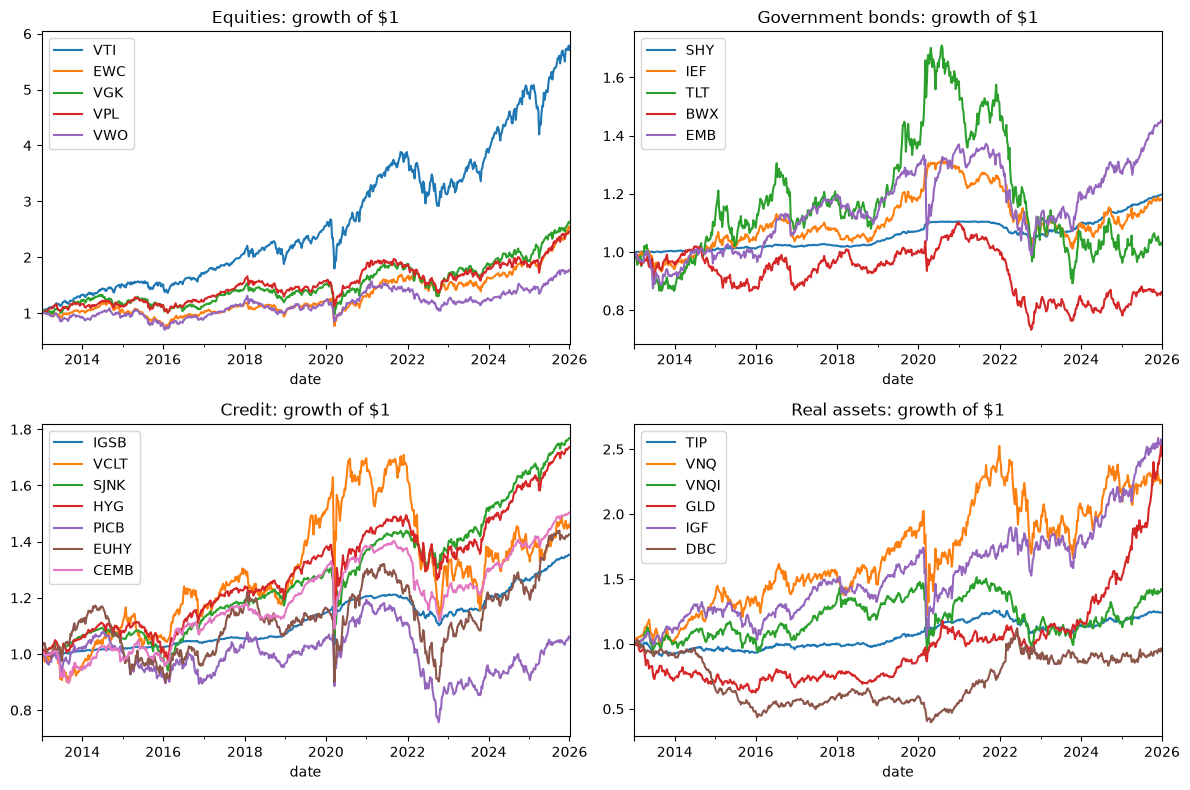

In [3]:
import matplotlib.pyplot as plt

blocks = {
    "Equities": ["VTI", "EWC", "VGK", "VPL", "VWO"],
    "Government bonds": ["SHY", "IEF", "TLT", "BWX", "EMB"],
    "Credit": ["IGSB", "VCLT", "SJNK", "HYG", "PICB", "EUHY", "CEMB"],
    "Real assets": ["TIP", "VNQ", "VNQI", "GLD", "IGF", "DBC"],
}

# Growth of $1
growth = (1 + risky_returns).cumprod()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, cols) in zip(axes.flat, blocks.items()):
    growth[cols].plot(ax=ax, title=f"{name}: growth of $1")
plt.tight_layout()

Text(0.5, 1.0, 'Weekly excess-return correlations')

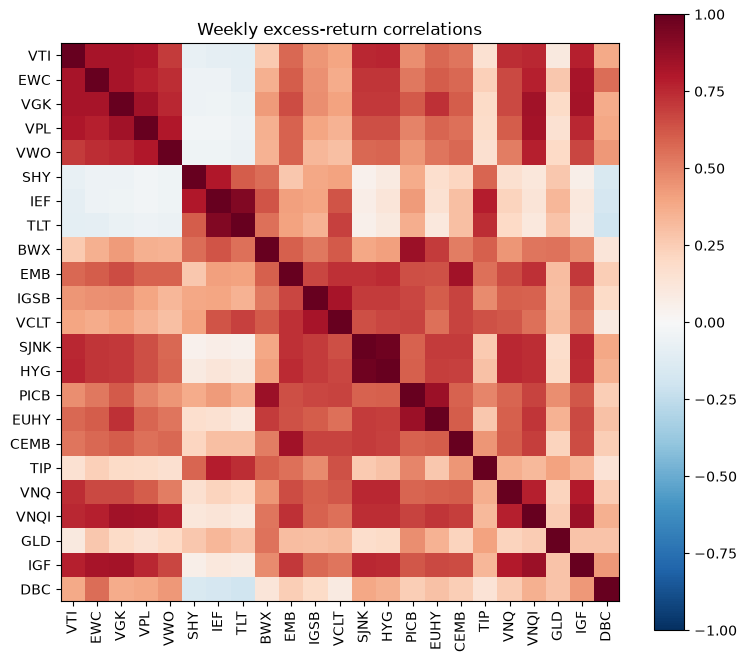

In [ ]:
plt.figure(figsize=(9, 8))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(lw_cov)), lw_cov.columns, rotation=90)
plt.yticks(range(len(lw_cov)), lw_cov.columns)
plt.colorbar()
plt.title("Weekly excess-return Ledoit-Wolf Correlations")

In [ ]:
optimize.min_variance(lw_cov)